In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256)


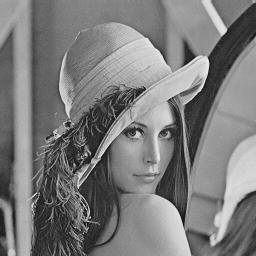

In [54]:
img = cv2.imread('/content/gdrive/My Drive/colabIP_26/images/lena256.jpg')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gimg1 = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print(gimg1.shape)
cv2_imshow(gimg1)

In [3]:
gx = np.array([[-1,0],[0,1]], dtype=int)
gy = np.array([[0, -1],[1,0]], dtype=int)
print(gx)
print(gy)

[[-1  0]
 [ 0  1]]
[[ 0 -1]
 [ 1  0]]


In [4]:
x = cv2.filter2D(gimg1, -1, gx)
y = cv2.filter2D(gimg1, -1, gy)


In [10]:
absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

In [8]:
absX = absX * 3
absY = absY * 3

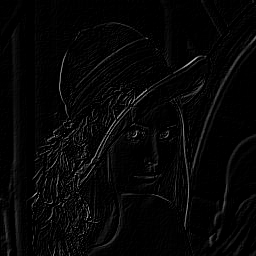

In [11]:
cv2_imshow(absX)

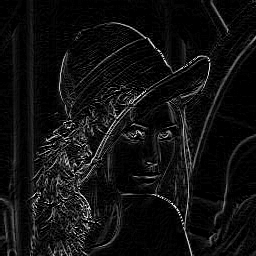

In [21]:
outImg = cv2.addWeighted(absX, 0.5, absY, 0.5, 0)
outImg = outImg * 3
cv2_imshow(outImg)

In [32]:
gBin = np.zeros(gimg1.shape, dtype=np.uint8)

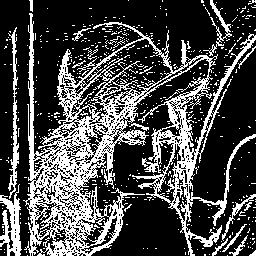

In [33]:
threshld = 15

for h in range(gimg1.shape[0]):
  for w in range(gimg1.shape[1]):
    if outImg[h,w] > threshld:
      gBin[h,w] = 255

cv2_imshow(gBin)

In [40]:
gx = np.array([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=int)
gy = np.array([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=int)

In [41]:
x = cv2.filter2D(gimg1, -1, gx)
y = cv2.filter2D(gimg1, -1, gy)

absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

In [42]:
gBin = np.zeros(gimg1.shape, dtype=np.uint8)

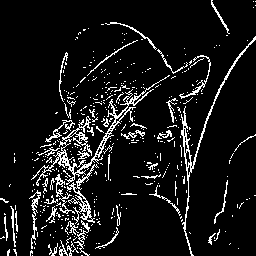

In [43]:
threshld = 50

for h in range(gimg1.shape[0]):
  for w in range(gimg1.shape[1]):
    if outImg[h,w] > threshld:
      gBin[h,w] = 255

cv2_imshow(gBin)

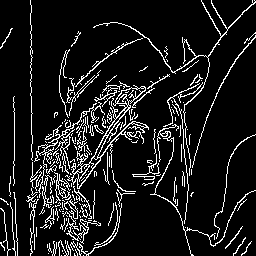

In [44]:
cannyimg = cv2.Canny(gimg1, 100, 200)
cv2_imshow(cannyimg)

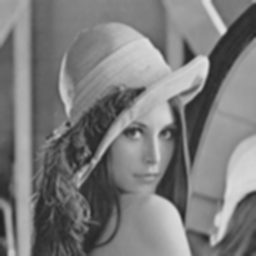

In [55]:
blurimg = cv2.GaussianBlur(gimg1,(5,5),1.4)
cv2_imshow(blurimg)

In [56]:
x = cv2.filter2D(blurimg, -1, gx)
y = cv2.filter2D(blurimg, -1, gy)

In [57]:
edgeDirection = np.arctan2(y,x)
print(edgeDirection)
print(edgeDirection.shape)

[[0.     0.     0.     ... 0.     0.     0.    ]
 [0.     0.     0.     ... 0.     0.     0.    ]
 [0.     0.     0.     ... 0.     0.     0.    ]
 ...
 [0.     0.     0.     ... 0.8804 1.107  1.57  ]
 [0.     0.     0.     ... 0.611  0.8623 1.57  ]
 [0.     0.     0.     ... 0.     0.     0.    ]]
(256, 256)


In [58]:
angle = np.rad2deg(edgeDirection)
print(angle)

[[ 0.    0.    0.   ...  0.    0.    0.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]
 ...
 [ 0.    0.    0.   ... 50.44 63.44 90.  ]
 [ 0.    0.    0.   ... 35.   49.4  90.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]]
